# Serving LLMs with vLLM — Practical Lab

---
## Block 0 · Setup

In [ ]:
!pip -q install vllm==0.20.2 openai requests pandas matplotlib
!nvidia-smi --query-gpu=name,memory.total,memory.used --format=csv

In [2]:
import os, time, json, re, gc, sys, subprocess
import pandas as pd, matplotlib.pyplot as plt

MODEL = "Qwen/Qwen2.5-1.5B-Instruct"     # small, standard architecture: works out of the box with vLLM

---
## Block 1 · Offline inference: the `LLM` class

vLLM can be used in two ways:
- **Offline**: a Python library. You give it a list of prompts, it returns all the completions. Good for batch jobs (evaluation, data generation).
- **Online**: an HTTP server with an OpenAI-compatible API (Blocks 3–7).

Both use the **same engine and the same parameters**, so the offline API is the best place to learn them.

### The naive baseline: Hugging Face `generate`, one request at a time
🔮 **Predict:** how many tokens per second do we get by looping over 8 prompts?

In [2]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

PROMPTS = [f"Write a short story about a robot named Unit-{i}." for i in range(8)]
MAX_TOKENS = 64

hf_tok = AutoTokenizer.from_pretrained(MODEL, padding_side="left")   # pad on the left: generation continues on the right
if hf_tok.pad_token is None:
    hf_tok.pad_token = hf_tok.eos_token
hf_model = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.float16, device_map="cuda").eval()

t0 = time.perf_counter()
inputs = hf_tok(PROMPTS, return_tensors="pt", padding=True).to("cuda")   # all 8 prompts in one padded tensor
hf_model.generate(**inputs, max_new_tokens=MAX_TOKENS, min_new_tokens=MAX_TOKENS,
                  do_sample=False, pad_token_id=hf_tok.pad_token_id)
hf_time = time.perf_counter() - t0
hf_tps = len(PROMPTS) * MAX_TOKENS / hf_time
print(f"HF batched: {len(PROMPTS)} requests in {hf_time:.1f}s -> {hf_tps:.0f} tokens/s")


/home/lpozzi/Git/data-science-lectures/llm_in_prod/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 338/338 [00:00<00:00, 673.71it/s]


HF batched: 8 requests in 1.5s -> 343 tokens/s


### Engine parameters: `LLM(...)`

These are set **once**, when the engine starts (the same names exist as server flags: `max_model_len` → `--max-model-len`).
For now we use reasonable values: **Block 2** changes them one at a time and shows what each one does.

🔮 Watch the cell output: vLLM prints a lot of **startup logs**. We read them in Block 2.

In [3]:
from vllm import LLM, SamplingParams

llm = LLM(
    model=MODEL,
    dtype="auto",                  # use the dtype in the model config (bfloat16 here; float16 on older GPUs)
    max_model_len=4096,            # each request: prompt + output <= 4096 tokens
    gpu_memory_utilization=0.85,   # vLLM may use 85% of GPU memory;
    max_num_seqs=256,              # at most 256 requests decoded together
    seed=0,
)

INFO 11-09 15:31:37 [api_utils.py:286] non-default args: {'max_model_len': 4096, 'gpu_memory_utilization': 0.85, 'max_num_seqs': 256, 'disable_log_stats': True, 'model': 'Qwen/Qwen2.5-1.5B-Instruct'}
INFO 11-09 15:31:38 [model.py:692] Resolved architecture: Qwen2ForCausalLM
INFO 11-09 15:31:38 [model.py:2030] Using max model len 4096
INFO 11-09 15:31:38 [scheduler.py:288] Chunked prefill is enabled with max_num_batched_tokens=8192.
INFO 11-09 15:31:40 [kernel.py:416] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['native'], fused_add_rms_norm=['native'], gelu_and_mul_sparse=['triton', 'native'])
(EngineCore pid=568838) INFO 11-09 15:31:42 [core.py:123] Initializing a V1 LLM engine (v0.30.0) with config: model='Qwen/Qwen2.5-1.5B-Instruct', speculative_config=None, tokenizer='Qwen/Qwen2.5-1.5B-Instruct', skip_tokenizer_init=False, tokenizer_mode=auto, revision=main, tokenizer_revision=main, trust_remote_code=False, dtype=torch.bfloat16, max_seq_len=409

Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  1.15it/s]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  1.14it/s]
(EngineCore pid=568838) 


(EngineCore pid=568838) INFO 11-09 15:31:46 [default_loader.py:430] Loading weights took 0.96 seconds
(EngineCore pid=568838) INFO 11-09 15:31:46 [model_runner.py:428] Model loading took 2.98 GiB memory and 2.998065 seconds
(EngineCore pid=568838) INFO 11-09 15:31:46 [topk_topp_sampler.py:78] Using FlashInfer for top-p & top-k sampling.
(EngineCore pid=568838) INFO 11-09 15:31:46 [utils.py:320] Using LBNHC KV cache layout.
(EngineCore pid=568838) INFO 11-09 15:31:47 [caching.py:343] reconstructed serializable fn from standalone compile artifacts. num_artifacts=3 num_submods=29
(EngineCore pid=568838) INFO 11-09 15:31:47 [decorators.py:313] Directly load AOT compilation from path /home/lpozzi/.cache/vllm/torch_compile_cache/torch_aot_compile/3cb079a033e467214521d9a63c27d8effedbf95c2cdce670bf38e6bd22a5e191/rank_0_0/model
(EngineCore pid=568838) INFO 11-09 15:31:47 [monitor.py:53] torch.compile took 0.21 s in total
(EngineCore pid=568838) INFO 11-09 15:31:47 [monitor.py:81] Initial profil

Capturing CUDA graphs (FULL): 100%|██████████| 2/2 [00:00<00:00, 31.94it/s]


(EngineCore pid=568838) INFO 11-09 15:31:52 [model_runner.py:1066] Graph capturing finished in 3 secs, took 0.29 GiB
(EngineCore pid=568838) INFO 11-09 15:31:52 [gpu_worker.py:640] Available KV cache memory: 2.41 GiB
(EngineCore pid=568838) INFO 11-09 15:31:52 [gpu_worker.py:655] CUDA graph memory profiling is enabled (default since v0.21.0). The current --gpu-memory-utilization=0.8500 is equivalent to --gpu-memory-utilization=0.8047 without CUDA graph memory profiling. To maintain the same effective KV cache size as before, increase --gpu-memory-utilization to 0.8953. To disable, set VLLM_MEMORY_PROFILER_ESTIMATE_CUDAGRAPHS=0.
(EngineCore pid=568838) INFO 11-09 15:31:52 [kv_cache_utils.py:2395] GPU KV cache size: 90,272 tokens, Maximum concurrency for 4,096 tokens per request: 22.04x
(EngineCore pid=568838) INFO 11-09 15:31:52 [kernel_warmup.py:172] JIT kernel warmup starting.
(EngineCore pid=568838) INFO 11-09 15:31:52 [kernel_warmup.py:185] JIT kernel warmup finished in 0.00s.


Capturing CUDA graphs (FULL): 100%|██████████| 35/35 [00:00<00:00, 39.01it/s]


(EngineCore pid=568838) INFO 11-09 15:31:57 [model_runner.py:1066] Graph capturing finished in 4 secs, took 0.20 GiB
(EngineCore pid=568838) INFO 11-09 15:31:57 [gpu_worker.py:825] CUDA graph pool memory: 0.2 GiB (actual), 0.35 GiB (estimated), difference: 0.14 GiB (71.8%).
(EngineCore pid=568838) INFO 11-09 15:31:57 [gpu_worker.py:888] Free memory on device (7.51/7.62 GiB) on startup. Desired GPU memory utilization is (0.85, 6.48 GiB). Actual usage is 3.24 GiB for consumed memory (weights + non-torch), 0.83 GiB for peak activation, and 0.2 GiB for CUDAGraph memory. Replace gpu_memory_utilization config with `--kv-cache-memory=2215035802` (2.06 GiB) to fit into requested memory, or `--kv-cache-memory=3321031168` (3.09 GiB) to fully utilize gpu memory. Current kv cache memory in use is 2.41 GiB.
(EngineCore pid=568838) INFO 11-09 15:31:58 [jit_monitor.py:85] Kernel JIT monitor activated; monitored JIT compilations during inference will use mode=warn.
(EngineCore pid=568838) INFO 11-09 1

### Sampling parameters: `SamplingParams(...)`

These are set **per request**: every request can have different ones.

🔮 **Predict:** same 8 prompts, same 64 tokens. How much faster than the HF loop?

In [4]:
# Same workload as the HF baseline: greedy, exactly 64 tokens
MAX_TOKENS = 64
PROMPTS = [f"Write a short story about a robot named Unit-{i}." for i in range(8)]

bench_params = SamplingParams(temperature=0, max_tokens=MAX_TOKENS, ignore_eos=True)

t0 = time.perf_counter()
outputs = llm.generate(PROMPTS, bench_params)          # the whole list at once
t = time.perf_counter() - t0
print(f"vLLM: {len(PROMPTS)} requests in {t:.2f}s -> {len(PROMPTS) * MAX_TOKENS / t:.0f} tokens/s ")

Processed prompts: 100%|██████████| 8/8 [00:00<00:00,  8.87it/s, est. speed input: 106.71 toks/s, output: 569.09 toks/s]

vLLM: 8 requests in 0.92s -> 559 tokens/s 


In [5]:
# Now 32x more requests. Does the time grow 32x?
many = [f"Write a short story about a robot named Unit-{i}." for i in range(256)]

t0 = time.perf_counter()
outputs = llm.generate(many, bench_params)
t = time.perf_counter() - t0
n_tokens = sum(len(o.outputs[0].token_ids) for o in outputs)
print(f"vLLM: {len(many)} requests in {t:.2f}s -> {n_tokens / t:,.0f} tokens/s")

Processed prompts: 100%|██████████| 256/256 [00:01<00:00, 145.33it/s, est. speed input: 1973.70 toks/s, output: 9308.27 toks/s]

vLLM: 256 requests in 1.82s -> 9,022 tokens/s


### What comes back: `RequestOutput`

In [6]:
# n, stop and max_tokens: several completions, and two different finish reasons
params = SamplingParams(n=3, temperature=1.0, max_tokens=40, stop=["."], seed=1)
for i, c in enumerate(llm.generate(["My favourite Italian dish is"], params)[0].outputs):
    print(f"[{i}] finish={c.finish_reason:6}  {c.text!r}")

Processed prompts: 100%|██████████| 3/3 [00:00<00:00,  9.43it/s, est. speed input: 47.47 toks/s, output: 126.59 toks/s]

[0] finish=stop    '____'
[1] finish=stop    " the risotto，a dish that I attended at my friend's birthday party"
[2] finish=stop    ' Italian hải thích ⏰\nwhich translated into Vietnamese is "my favorite Italian dish is Italian sea food"'


✏️ **Try at home**
- Change `temperature`, `top_k`, `repetition_penalty` and compare outputs with the same `seed`.
- Increase the batch to 1,024 prompts: does throughput keep growing?

**Takeaway:** one engine, two kinds of parameters: **engine** parameters (set at startup) and **sampling** parameters (per request).

---
## Block 2 · Engine parameters: what each one changes

vLLM gets a **fixed amount of GPU memory** and must divide it. Every engine parameter answers one question
about how that memory is divided, or how it is shared between requests.

```
GPU memory (e.g. 8 GB)
┌──────────────────────── gpu_memory_utilization × total ─────────────────────────┬───────────┐
│  weights              │ activations │  KV cache pool (pages of 16 tokens)         │ left free │
│  dtype, quantization  │  (peak)     │  shared by all the requests in flight       │           │
└───────────────────────┴─────────────┴─────────────────────────────────────────────┴───────────┘
```

| Question | Parameter | What it changes |
|---|---|---|
| How big are the weights? | `dtype`, `quantization` | the weights block |
| How much of the GPU may vLLM take? | `gpu_memory_utilization` | the whole box, and so the KV pool |
| How many bytes per cached token? | `kv_cache_dtype` | how many tokens fit in the KV pool |
| How long can one request be? | `max_model_len` | the share of the pool one request may need |
| How many requests per step? | `max_num_seqs` | how many requests share each decoding step |
| How many tokens per step? | `max_num_batched_tokens` | how much prompt (prefill) work fits in one step |
| Fast startup or fast decoding? | `enforce_eager` | CUDA graphs on / off |

First we read these numbers in the startup logs, then we change each parameter and measure what happens.

### 2.1 Reading the startup logs

Scroll back to the output of the `LLM(...)` cell. Look for these lines (exact wording changes between versions):

| Log line | Meaning |
|---|---|
| `Using max model len 4096` | Our `max_model_len` |
| `Model loading took X GiB` | Memory for the **weights** (1.5B params × 2 bytes ≈ 3 GiB) |
| `Available KV cache memory: X GiB` | What is left for the **KV cache** after weights and a profiling run for activations |
| `GPU KV cache size: N tokens` | How many tokens fit in the KV cache pool (all requests together) |
| `Maximum concurrency for 4,096 tokens per request: Yx` | N / max_model_len: how many **full-length** requests fit at once |
| `Capturing CUDA graphs ...` | Pre-recording GPU kernels to speed up decoding (skipped with `enforce_eager=True`) |

### Check the numbers ourselves
KV cache per token = 2 (K and V) × layers × KV heads × head dim × bytes per value
(2 bytes in bfloat16 / float16, **1 byte** with `kv_cache_dtype="fp8"`).

In [7]:
from transformers import AutoConfig

cfg = AutoConfig.from_pretrained(MODEL)
head_dim = cfg.hidden_size // cfg.num_attention_heads
bytes_per_value = 2                                   # bfloat16 / float16
kv_bytes_per_token = 2 * cfg.num_hidden_layers * cfg.num_key_value_heads * head_dim * bytes_per_value

print(f"layers={cfg.num_hidden_layers}, KV heads={cfg.num_key_value_heads} (query heads={cfg.num_attention_heads}), head_dim={head_dim}")
print(f"KV cache per token: {kv_bytes_per_token:,} bytes = {kv_bytes_per_token / 1024:.0f} KiB")

KV_CACHE_GIB = 8.0      # <- copy the value from the log line "Available KV cache memory: X GiB"
tokens = KV_CACHE_GIB * 1024**3 / kv_bytes_per_token
print(f"\n{KV_CACHE_GIB} GiB / {kv_bytes_per_token / 1024:.0f} KiB = {tokens:,.0f} tokens "
      f"= {tokens / 16:,.0f} blocks of 16 tokens")
print(f"Full-length requests at once: {tokens / 4096:.1f}   (compare with 'Maximum concurrency')")

layers=28, KV heads=2 (query heads=12), head_dim=128
KV cache per token: 28,672 bytes = 28 KiB

8.0 GiB / 28 KiB = 299,593 tokens = 18,725 blocks of 16 tokens
Full-length requests at once: 73.1   (compare with 'Maximum concurrency')


### 2.2 One parameter at a time

Each experiment starts the **default engine** and a copy with **one parameter changed**, and measures:

| Measure | How |
|---|---|
| startup (s) | time to build `LLM(...)` |
| GPU used (GiB) | `nvidia-smi` after startup |
| weights / KV cache (GiB), KV cache (tokens), max concurrency | parsed from the startup logs |
| throughput (tok/s) | 256 short prompts × 64 generated tokens: **decode**-heavy |
| prefill (tok/s) | 32 prompts of 2,000 tokens × 1 generated token: **prefill**-heavy |
| single request (tok/s) | 1 prompt × 256 tokens: the speed one user sees |
| 5k-token prompt | does a 5,000-token prompt get accepted? |

Every engine runs in a **separate process** (vLLM does not reliably free GPU memory inside the notebook), and its
results are saved in `engine_results/`: run the experiments **before class** (about 1–2 minutes each) and
the cells only show the saved results. Pass `rerun=True` to run one again.

⚠️ First free the GPU: **Runtime → Restart session**, then run the Block 0 cells and the cells below.

In [1]:
import os 
import json
import pandas as pd

PROBE = r"""
import json, random, subprocess, sys, time

def gpu_used_gib():
    out = subprocess.run(["nvidia-smi", "--query-gpu=memory.used", "--format=csv,noheader,nounits"],
                         capture_output=True, text=True).stdout
    return round(int(out.split()[0]) / 1024, 2)

def random_prompt(seed, n):
    # random token ids: no two prompts share a prefix, so prefix caching cannot skip the work
    return {"prompt_token_ids": random.Random(seed).choices(range(1000, 20000), k=n)}

def main():
    from vllm import LLM, SamplingParams
    args = json.loads(sys.argv[1])
    res = {}

    t0 = time.perf_counter()
    llm = LLM(seed=0, **args)
    res["startup (s)"] = round(time.perf_counter() - t0, 1)
    res["GPU used (GiB)"] = gpu_used_gib()
    try:
        res["max_num_batched_tokens"] = llm.llm_engine.vllm_config.scheduler_config.max_num_batched_tokens
    except Exception:
        pass

    def timed(prompts, params):
        t0 = time.perf_counter()
        outs = llm.generate(prompts, params, use_tqdm=False)
        return outs, time.perf_counter() - t0

    timed(["Hello"], SamplingParams(max_tokens=8))                                   # warm-up

    # 1. throughput: 256 short prompts x 64 tokens (decode-heavy)
    prompts = [f"Write a short story about a robot named Unit-{i}." for i in range(256)]
    outs, t = timed(prompts, SamplingParams(temperature=0, max_tokens=64, ignore_eos=True))
    res["throughput (tok/s)"] = round(sum(len(o.outputs[0].token_ids) for o in outs) / t)

    # 2. prefill: 32 prompts of 2,000 tokens x 1 token (prefill-heavy)
    _, t = timed([random_prompt(i, 2000) for i in range(32)], SamplingParams(max_tokens=1))
    res["prefill (tok/s)"] = round(32 * 2000 / t)

    # 3. one request: what a single user sees
    outs, t = timed(["Explain the KV cache."], SamplingParams(temperature=0, max_tokens=256, ignore_eos=True))
    res["single request (tok/s)"] = round(len(outs[0].outputs[0].token_ids) / t)

    # 4. a prompt longer than the default max_model_len
    try:
        timed([random_prompt(999, 5000)], SamplingParams(max_tokens=1))
        res["5k-token prompt"] = "ok"
    except Exception as e:
        res["5k-token prompt"] = "error: " + str(e)[:90]

    print("RESULT " + json.dumps(res), flush=True)

if __name__ == "__main__":      # vLLM starts the engine in a child process: the guard keeps it from re-running this file
    main()
"""
open("engine_probe.py", "w").write(PROBE)
os.makedirs("engine_results", exist_ok=True)
MODEL = "Qwen/Qwen2.5-1.5B-Instruct"
DEFAULT = dict(model=MODEL, gpu_memory_utilization=0.85, max_model_len=4096, max_num_seqs=256)
RESULTS = {}

def run_engine(name, rerun=False, verbose=False, **changes):
    """Start the default engine with `changes` applied, in a separate process. Results are cached on disk."""
    os.makedirs("engine_results", exist_ok=True)          # <- new
    path = f"engine_results/{name}.json"
    if os.path.exists(path) and not rerun:
        RESULTS[name] = json.load(open(path))
        return RESULTS[name]
    args = {**DEFAULT, **changes}
    proc = subprocess.Popen([sys.executable, "engine_probe.py", json.dumps(args)],
                            stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    lines = []
    for line in proc.stdout:                       # stream the engine logs as they are produced
        lines.append(line)
        if verbose: print(line, end="")
    proc.wait()
    logs, r = "".join(lines), proc
    open(f"engine_results/{name}.log", "w").write(logs)          # full logs, for debugging
    find = lambda pattern: (re.findall(pattern, logs) or ["-"])[-1]

    res = {"changed": ", ".join(f"{k}={v}" for k, v in changes.items()) or "(default)",
           "weights (GiB)": find(r"Model loading took ([\d.]+) ?GiB"),
           "KV cache (GiB)": find(r"Available KV cache memory: ([\d.]+) ?GiB"),
           "KV cache (tokens)": find(r"KV cache size: ([\d,]+) tokens"),
           "max concurrency": find(r"Maximum concurrency for [\d,]+ tokens per request: ([\d.]+)x")}
    line = [l for l in logs.splitlines() if l.startswith("RESULT ")]
    if line:
        res.update(json.loads(line[-1][len("RESULT "):]))
    else:                                         # the engine did not start: keep the error message
        errors = [re.sub(r"^\(EngineCore[^)]*\) (ERROR .*?\] )?", "", l) for l in logs.splitlines() if "Error:" in l]
        root = [e for e in errors if not e.startswith("RuntimeError: Engine core")]   # skip the generic wrapper error
        res["error"] = (root or errors or [f"exit code {r.returncode}"])[-1]          # full root-cause message
        print(f"[{name}] failed. Last lines of engine_results/{name}.log:\n" + "\n".join(logs.splitlines()[-15:]))
    json.dump(res, open(path, "w"), indent=1)
    RESULTS[name] = res
    return res

def compare(*names, cols=None):
    """Table of the saved runs, with only the columns that matter for this experiment."""
    df = pd.DataFrame({n: RESULTS[n] for n in names}).T
    cols = ["changed"] + [c for c in (cols or []) if c not in ("changed", "error")] + (["error"] if "error" in df else [])
    out = df[[c for c in cols if c in df]].fillna("")
    return out.style.set_properties(**{"text-align": "left", "white-space": "normal"})   # Styler: shows the full error text

In [3]:
import json, random, subprocess, sys, re, time

run_engine("default", verbose=True)          # run the default engine, and save the results to engine_results/default.json
pd.DataFrame(RESULTS["default"], index=["default"]).T          # all the measures of the default engine

,default
changed,(default)
weights (GiB),2.98
KV cache (GiB),2.41
KV cache (tokens),"90,272"
max concurrency,22.04
startup (s),20.2
GPU used (GiB),6.2
max_num_batched_tokens,8192
throughput (tok/s),9050
prefill (tok/s),14294


#### ① `quantization`: smaller weights
The same model with **4-bit AWQ weights** (a pre-quantized checkpoint: vLLM reads the method from its config,
so no `quantization=` argument is needed). Quantization methods are the topic of a later lab: here we only look at memory.

🔮 **Predict:** the weights get about 3× smaller. Where does the saved memory go?

In [4]:
import json, random, subprocess, sys, re, time

run_engine("awq", model="Qwen/Qwen2.5-1.5B-Instruct-AWQ", verbose=True)
compare("default", "awq", cols=["weights (GiB)", "KV cache (GiB)", "KV cache (tokens)", "GPU used (GiB)", "throughput (tok/s)"])

INFO 11-09 15:54:29 [api_utils.py:286] non-default args: {'max_model_len': 4096, 'gpu_memory_utilization': 0.85, 'max_num_seqs': 256, 'disable_log_stats': True, 'model': 'Qwen/Qwen2.5-1.5B-Instruct-AWQ'}
INFO 11-09 15:54:30 [model.py:692] Resolved architecture: Qwen2ForCausalLM
INFO 11-09 15:54:30 [model.py:2030] Using max model len 4096
INFO 11-09 15:54:31 [scheduler.py:288] Chunked prefill is enabled with max_num_batched_tokens=8192.
INFO 11-09 15:54:33 [kernel.py:416] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['native'], fused_add_rms_norm=['native'], gelu_and_mul_sparse=['triton', 'native'])
(EngineCore pid=581180) INFO 11-09 15:54:35 [core.py:123] Initializing a V1 LLM engine (v0.30.0) with config: model='Qwen/Qwen2.5-1.5B-Instruct-AWQ', speculative_config=None, tokenizer='Qwen/Qwen2.5-1.5B-Instruct-AWQ', skip_tokenizer_init=False, tokenizer_mode=auto, revision=main, tokenizer_revision=main, trust_remote_code=False, dtype=torch.float16, max_

/tmp/ipykernel_580211/589585394.py:109: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  out = df[[c for c in cols if c in df]].fillna("")


,changed,weights (GiB),KV cache (GiB),KV cache (tokens),GPU used (GiB),throughput (tok/s)
default,(default),2.98,2.41,"90,272",6.200000,9050
awq,model=Qwen/Qwen2.5-1.5B-Instruct-AWQ,1.1,4.32,"161,808",6.220000,10114


- **Weights** shrink, but **GPU used** stays about the same: vLLM still takes its `gpu_memory_utilization` share.
- The saved memory goes to the **KV cache**: more tokens, more requests at once.
- Throughput may go up or down: 4-bit weights are read faster, but must be dequantized on the fly.

#### ② `gpu_memory_utilization`: how much of the GPU vLLM takes
🔮 **Predict:** with 0.65 instead of 0.85, what gets smaller: the weights or the KV cache?
And with a value so low that the weights alone don't fit?

In [5]:
import json, random, subprocess, sys, re, time

total_gib = int(subprocess.run(["nvidia-smi", "--query-gpu=memory.total", "--format=csv,noheader,nounits"],
                               capture_output=True, text=True).stdout.split()[0]) / 1024
too_low = round(2.0 / total_gib, 2)          # 2 GiB: less than the ~3 GiB of weights
print(f"GPU: {total_gib:.1f} GiB -> too low = {too_low}")

run_engine("default")
run_engine("util_too_low", gpu_memory_utilization=too_low, verbose=True)
df = compare("default", "util_0.65", "util_too_low",
        cols=["GPU used (GiB)", "weights (GiB)", "KV cache (GiB)", "KV cache (tokens)", "max concurrency"])

df

GPU: 8.0 GiB -> too low = 0.25
INFO 11-09 15:55:29 [api_utils.py:286] non-default args: {'max_model_len': 4096, 'gpu_memory_utilization': 0.25, 'max_num_seqs': 256, 'disable_log_stats': True, 'model': 'Qwen/Qwen2.5-1.5B-Instruct'}
INFO 11-09 15:55:31 [model.py:692] Resolved architecture: Qwen2ForCausalLM
INFO 11-09 15:55:31 [model.py:2030] Using max model len 4096
INFO 11-09 15:55:31 [scheduler.py:288] Chunked prefill is enabled with max_num_batched_tokens=8192.
INFO 11-09 15:55:32 [kernel.py:416] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['native'], fused_add_rms_norm=['native'], gelu_and_mul_sparse=['triton', 'native'])
(EngineCore pid=581685) INFO 11-09 15:55:35 [core.py:123] Initializing a V1 LLM engine (v0.30.0) with config: model='Qwen/Qwen2.5-1.5B-Instruct', speculative_config=None, tokenizer='Qwen/Qwen2.5-1.5B-Instruct', skip_tokenizer_init=False, tokenizer_mode=auto, revision=main, tokenizer_revision=main, trust_remote_code=False, dtype=

KeyError: 'util_0.65'

- The **weights don't change**: only the KV pool shrinks, so fewer tokens and fewer requests at once.
- **GPU used** follows the parameter: vLLM reserves its share at startup, whatever the model size.
- Too low: the engine **refuses to start**. The error says there is no memory left for the KV cache.
- Use a lower value when something else needs the GPU (a second model, a notebook, your desktop).

#### ③ `kv_cache_dtype`: bytes per cached token
`"fp8"` stores keys and values in 1 byte instead of 2. The weights are untouched.
Not every GPU supports it: if yours doesn't, the row shows the error.

🔮 **Predict:** how many more tokens fit in the KV cache?

In [6]:
run_engine("kv_fp8", kv_cache_dtype="fp8", verbose=True)
compare("default", "kv_fp8", cols=["KV cache (GiB)", "KV cache (tokens)", "max concurrency", "throughput (tok/s)"])

INFO 11-09 15:56:03 [api_utils.py:286] non-default args: {'kv_cache_dtype': 'fp8', 'max_model_len': 4096, 'gpu_memory_utilization': 0.85, 'max_num_seqs': 256, 'disable_log_stats': True, 'model': 'Qwen/Qwen2.5-1.5B-Instruct'}
INFO 11-09 15:56:04 [model.py:692] Resolved architecture: Qwen2ForCausalLM
INFO 11-09 15:56:04 [model.py:2030] Using max model len 4096
INFO 11-09 15:56:04 [cache.py:343] Using fp8 data type to store kv cache. It reduces the GPU memory footprint and boosts the performance. Meanwhile, it may cause accuracy drop without a proper scaling factor
INFO 11-09 15:56:04 [scheduler.py:288] Chunked prefill is enabled with max_num_batched_tokens=8192.
INFO 11-09 15:56:05 [kernel.py:416] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['native'], fused_add_rms_norm=['native'], gelu_and_mul_sparse=['triton', 'native'])
(EngineCore pid=582072) INFO 11-09 15:56:07 [core.py:123] Initializing a V1 LLM engine (v0.30.0) with config: model='Qwen/Qwen2.

/tmp/ipykernel_580211/589585394.py:109: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  out = df[[c for c in cols if c in df]].fillna("")


,changed,KV cache (GiB),KV cache (tokens),max concurrency,throughput (tok/s)
default,(default),2.41,"90,272",22.04,9050
kv_fp8,kv_cache_dtype=fp8,1.64,"123,200",30.08,8812


- Same **GiB** of KV cache, for more concurrencies.
- The price is precision: a small quality loss, usually negligible (check it on your task).
- The other way to the same goal: `quantization` shrinks the weights (①), `kv_cache_dtype` shrinks the cache.

#### ④ `max_model_len`: the longest request
🔮 **Predict:** with `max_model_len=32768` instead of 4096, does the KV cache get bigger?
What happens to the 5,000-token prompt?

In [7]:
run_engine("len_32k", max_model_len=32768, verbose=True)
compare("default", "len_32k", cols=["KV cache (tokens)", "max concurrency", "5k-token prompt"])

INFO 11-09 15:57:12 [api_utils.py:286] non-default args: {'max_model_len': 32768, 'gpu_memory_utilization': 0.85, 'max_num_seqs': 256, 'disable_log_stats': True, 'model': 'Qwen/Qwen2.5-1.5B-Instruct'}
INFO 11-09 15:57:13 [model.py:692] Resolved architecture: Qwen2ForCausalLM
INFO 11-09 15:57:13 [model.py:2030] Using max model len 32768
INFO 11-09 15:57:13 [scheduler.py:288] Chunked prefill is enabled with max_num_batched_tokens=8192.
INFO 11-09 15:57:14 [kernel.py:416] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['native'], fused_add_rms_norm=['native'], gelu_and_mul_sparse=['triton', 'native'])
(EngineCore pid=582942) INFO 11-09 15:57:17 [core.py:123] Initializing a V1 LLM engine (v0.30.0) with config: model='Qwen/Qwen2.5-1.5B-Instruct', speculative_config=None, tokenizer='Qwen/Qwen2.5-1.5B-Instruct', skip_tokenizer_init=False, tokenizer_mode=auto, revision=main, tokenizer_revision=main, trust_remote_code=False, dtype=torch.bfloat16, max_seq_len=3

,changed,KV cache (tokens),max concurrency,5k-token prompt
default,(default),"90,272",22.04,"error: This model's maximum context length is 4096 tokens. However, you requested 0 output tokens"
len_32k,max_model_len=32768,"74,688",2.28,ok


- The **KV pool is the same**: `max_model_len` doesn't reserve memory, it sets a **limit per request**.
- **Max concurrency** drops: the same pool holds far fewer requests *of the maximum length*.
- With 4096 the 5,000-token prompt is **rejected** with an error; with 32,768 it is accepted.
- If the pool can't hold even **one** request of `max_model_len` tokens, vLLM refuses to start.
- Rule: set it to the longest request you really expect, not to the model's maximum.

#### ④b `max_model_len` when VRAM is tight
`max_model_len` is also the knob you turn when memory is short: the KV pool must fit **at least one** request of that length.
Let's squeeze the pool to about 0.5 GiB (a few tens of thousands of tokens) and ask for the 32k context again.

🔮 **Predict:** does the engine start with `max_model_len=32768`? And with `16384`?

In [ ]:
tight = round((3.0 + 1.3 + 0.5) / total_gib, 2)   # weights + profiling overhead + ~0.5 GiB left for the KV cache
print(f"gpu_memory_utilization = {tight}")

run_engine("tight_32k", gpu_memory_utilization=tight, max_model_len=32768, verbose=True)     # expected to fail
run_engine("tight_3k", gpu_memory_utilization=tight, max_model_len=3280, verbose=True)
compare("tight_32k", "tight_3k", cols=["KV cache (GiB)", "KV cache (tokens)", "max concurrency"])

gpu_memory_utilization = 0.6


,changed,KV cache (GiB),KV cache (tokens),max concurrency,error
tight_32k,"gpu_memory_utilization=0.6, max_model_len=32768",0.5,-,-,"ValueError: To serve at least one request with the model's max seq len (32768), (0.88 GiB KV cache is needed, which is larger than the available KV cache memory (0.5 GiB). Based on the available memory, the estimated maximum model length is 18864. Try increasing `gpu_memory_utilization` (which also controls CPU memory on the CPU backend) or decreasing `max_model_len` when initializing the engine. See https://docs.vllm.ai/en/latest/configuration/conserving_memory/ for more details."
tight_3k,"gpu_memory_utilization=0.6, max_model_len=3280",0.09,"3,296",1.00,


- With 32,768 the engine **does not start**: the error says how much KV cache one full-length request needs, and how much is available.
- Lowering `max_model_len` fixes it, at the price of rejecting longer requests. Same effect as freeing memory (quantized model, `fp8` KV cache, higher `gpu_memory_utilization`).
- Use the `KV cache (tokens)` figure as your budget: `max_model_len` must be **at most** that, ideally several times smaller so more requests run together.

#### ⑤ `max_num_seqs`: requests per step
At every step vLLM decodes one token for **every** running request. `max_num_seqs` caps how many run together;
the others wait in a queue.

🔮 **Predict:** same model, same memory, 256 prompts, but at most 8 at a time. How much slower?

In [13]:
run_engine("seqs_256_1k", n_requests=1024, verbose=True)                        # max_num_seqs=256 (default)
run_engine("seqs_512_1k", n_requests=1024, max_num_seqs=512, verbose=True)
run_engine("seqs_8_1k",   n_requests=1024, max_num_seqs=8,   verbose=True)

compare("seqs_8_1k", "seqs_256_1k", "seqs_512_1k",
        cols=["changed", "KV cache (tokens)", "throughput (tok/s)"])

INFO 11-09 16:14:14 [api_utils.py:286] non-default args: {'max_model_len': 4096, 'gpu_memory_utilization': 0.85, 'max_num_seqs': 256, 'disable_log_stats': True, 'model': 'Qwen/Qwen2.5-1.5B-Instruct'}
INFO 11-09 16:14:15 [model.py:692] Resolved architecture: Qwen2ForCausalLM
INFO 11-09 16:14:15 [model.py:2030] Using max model len 4096
INFO 11-09 16:14:15 [scheduler.py:288] Chunked prefill is enabled with max_num_batched_tokens=8192.
INFO 11-09 16:14:16 [kernel.py:416] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['native'], fused_add_rms_norm=['native'], gelu_and_mul_sparse=['triton', 'native'])
(EngineCore pid=589803) INFO 11-09 16:14:19 [core.py:123] Initializing a V1 LLM engine (v0.30.0) with config: model='Qwen/Qwen2.5-1.5B-Instruct', speculative_config=None, tokenizer='Qwen/Qwen2.5-1.5B-Instruct', skip_tokenizer_init=False, tokenizer_mode=auto, revision=main, tokenizer_revision=main, trust_remote_code=False, dtype=torch.bfloat16, max_seq_len=409

/tmp/ipykernel_580211/589585394.py:109: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  out = df[[c for c in cols if c in df]].fillna("")


KeyError: '`Styler.apply` and `.map` are not compatible with non-unique index or columns.'

- **Memory is unchanged**, but throughput collapses: each step reads all the weights to produce 8 tokens instead of 256.
- **One request alone** is as fast as before: batching doesn't make a single request faster, it serves **more** of them.
- This is why vLLM was faster than the HF loop in Block 1, and it is what Block 5 shows live on the server.

#### ⑦ `enforce_eager`: startup time vs decoding speed
By default vLLM **captures CUDA graphs** at startup: it records the GPU kernels of a decoding step once,
then replays them without Python overhead. `enforce_eager=True` skips this.

🔮 **Predict:** what gets faster, and what gets slower?

In [14]:
run_engine("eager", enforce_eager=True, verbose=True)
compare("default", "eager", cols=["startup (s)", "KV cache (tokens)", "single request (tok/s)", "throughput (tok/s)"])

INFO 11-09 16:18:04 [api_utils.py:286] non-default args: {'max_model_len': 4096, 'gpu_memory_utilization': 0.85, 'max_num_seqs': 256, 'disable_log_stats': True, 'enforce_eager': True, 'model': 'Qwen/Qwen2.5-1.5B-Instruct'}
INFO 11-09 16:18:06 [model.py:692] Resolved architecture: Qwen2ForCausalLM
INFO 11-09 16:18:06 [model.py:2030] Using max model len 4096
INFO 11-09 16:18:06 [scheduler.py:288] Chunked prefill is enabled with max_num_batched_tokens=8192.
WARNING 11-09 16:18:07 [vllm.py:1547] Enforce eager set, disabling torch.compile and CUDAGraphs. This is equivalent to setting -cc.mode=none -cc.cudagraph_mode=none
WARNING 11-09 16:18:07 [vllm.py:1570] Inductor compilation was disabled by user settings, optimizations settings that are only active during inductor compilation will be ignored.
INFO 11-09 16:18:07 [kernel.py:416] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['vllm_c', 'native'], fused_add_rms_norm=['vllm_c', 'native'], gelu_and_mul_spa

/tmp/ipykernel_580211/589585394.py:109: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  out = df[[c for c in cols if c in df]].fillna("")


,changed,startup (s),KV cache (tokens),single request (tok/s),throughput (tok/s)
default,(default),20.200000,"90,272",74,9050
eager,enforce_eager=True,12.500000,"102,336",73,8522


- **Startup** is faster (no graph capture, no compilation).
- **Decoding** is slower, most visibly for a **single request**: small steps are dominated by kernel-launch overhead.
- The KV cache gets slightly bigger: the graphs need some memory too.
- Use it when you restart often (debugging, these experiments); leave it off for serving.

### 2.3 All the runs together

In [16]:
for name in sorted(os.listdir("engine_results")):
    RESULTS[name[:-5]] = json.load(open(f"engine_results/{name}"))
compare(*RESULTS, cols=["weights (GiB)", "KV cache (tokens)", "max concurrency", "startup (s)",
                        "throughput (tok/s)", "prefill (tok/s)", "single request (tok/s)", "5k-token prompt"])

JSONDecodeError: Expecting value: line 1 column 1 (char 0)

### Rules of thumb

| Problem | Change |
|---|---|
| Out of memory at startup | lower `max_model_len`, use a quantized model or `kv_cache_dtype="fp8"`, or raise `gpu_memory_utilization` if the GPU is free |
| Low throughput | raise `max_num_seqs`; more KV cache (quantization, `fp8` KV cache) lets more requests run at once |
| Long prompts are rejected | raise `max_model_len`, which leaves room for fewer requests at once |
| Slow restarts while experimenting | `enforce_eager=True` (but not for serving) |

✏️ **Try at home:** find the smallest `gpu_memory_utilization` that still starts with `max_model_len=32768`.

**Takeaway:** serving capacity is decided by the **KV cache pool**. The engine parameters decide how big it is
and how it is shared, and the startup logs tell you exactly what you got.

---
## Block 3 · Serving with Docker  🖥️ *(terminal)*

The same engine, wrapped in an **OpenAI-compatible HTTP server**, shipped as the official image
[`vllm/vllm-openai`](https://hub.docker.com/r/vllm/vllm-openai).
A container gives the same CUDA, PyTorch and vLLM versions on every machine.

⚠️ The GPU must be free: shut down this notebook's kernel first if you ran Blocks 1–2 on the same GPU (Kernel → Shut down), then restart it.

### Start the server (in a terminal)
```bash
mkdir -p bench
docker run -d --name vllm-lab \
  --gpus all \
  --ipc=host \
  -p 8000:8000 \
  -v ~/.cache/huggingface:/root/.cache/huggingface \
  -v "$(pwd)/bench:/bench" \
  vllm/vllm-openai:v0.20.1 \
  --model Qwen/Qwen2.5-1.5B-Instruct \
  --max-model-len 8192 \
  --gpu-memory-utilization 0.85 \
  --max-num-seqs 32 
```

| Part | Why |
|---|---|
| `-d --name vllm-lab` | Run in the background with a fixed name |
| `--gpus all` | Give the container the GPUs (needs the NVIDIA Container Toolkit) |
| `--ipc=host` | PyTorch processes share memory; the default container limit is too small |
| `-p 8000:8000` | Host port → container port: the API is at `http://localhost:8000` |
| `-v ~/.cache/huggingface:...` | Reuse downloaded weights: no new download at each restart |
| `-v $(pwd)/bench:/bench` | A shared folder for the benchmark results (Block 7) |
| `-e HF_TOKEN` | Only needed for gated models |
| everything **after the image name** | Arguments of `vllm serve`: the **same engine parameters** as Block 1 |
| `--max-num-seqs 32` | Kept small on purpose, to see the waiting queue in Block 5 |
| `--api-key lab-secret` | Clients must send `Authorization: Bearer lab-secret` |

### Watch it start
```bash
docker logs -f vllm-lab      # the same startup logs as Block 2, then "Application startup complete"
```

### Useful commands
| Command | What it does |
|---|---|
| `docker ps` | Is the container running? |
| `docker logs -f vllm-lab` | Live logs: requests, throughput, KV cache usage every few seconds |
| `docker exec -it vllm-lab bash` | A shell inside the container |
| `docker exec vllm-lab nvidia-smi` | GPU usage seen from inside |
| `docker stop vllm-lab && docker rm vllm-lab` | Stop and delete it |

**How it fits together:**
```
client (curl / Python / any OpenAI SDK)
   │  HTTP :8000
   ▼
container: vllm serve ── API server (FastAPI) → scheduler → engine (PagedAttention) ── GPU
   │
   └─ volume: ~/.cache/huggingface (weights)
```

---
## Block 4 · Testing the endpoints

From here on the notebook is just an **HTTP client**: it doesn't need a GPU.

In [17]:
import requests

BASE_URL = os.environ.get("VLLM_URL", "http://localhost:8000")
API_KEY = "lab-secret"
HEADERS = {"Authorization": f"Bearer {API_KEY}"}
MODEL = "Qwen/Qwen2.5-1.5B-Instruct"

# Wait until the server is ready (loading + CUDA graphs take 1-2 minutes)
for _ in range(60):
    try:
        if requests.get(f"{BASE_URL}/health", timeout=2).status_code == 200:
            print("server ready"); break
    except requests.ConnectionError:
        pass
    time.sleep(5)

server ready


### Server info
| Endpoint | Method | Auth | Purpose |
|---|---|---|---|
| `/health` | GET | no | Liveness check (for Docker, Kubernetes, load balancers) |
| `/version` | GET | no | vLLM version |
| `/v1/models` | GET | yes | Which models are served |
| `/metrics` | GET | no | Prometheus metrics (Block 5) |

In [19]:
print("health :", requests.get(f"{BASE_URL}/health").status_code)
print("version:", requests.get(f"{BASE_URL}/version").json())

# 🔮 Without the API key?
r = requests.get(f"{BASE_URL}/v1/models")
print("\n/v1/models without key:", r.status_code, r.text[:80])
r = requests.get(f"{BASE_URL}/v1/models", headers=HEADERS)
print("/v1/models with key   :", r.status_code)
print(json.dumps(r.json(), indent=2))

health : 200
version: {'version': '0.20.1'}

/v1/models without key: 200 {"object":"list","data":[{"id":"Qwen/Qwen2.5-1.5B-Instruct","object":"model","cr
/v1/models with key   : 200
{
  "object": "list",
  "data": [
    {
      "id": "Qwen/Qwen2.5-1.5B-Instruct",
      "object": "model",
      "created": 1794237923,
      "owned_by": "vllm",
      "root": "Qwen/Qwen2.5-1.5B-Instruct",
      "parent": null,
      "max_model_len": 8192,
      "permission": [
        {
          "id": "modelperm-970c2f51f850010f",
          "object": "model_permission",
          "created": 1794237923,
          "allow_create_engine": false,
          "allow_sampling": true,
          "allow_logprobs": true,
          "allow_search_indices": false,
          "allow_view": true,
          "allow_fine_tuning": false,
          "organization": "*",
          "group": null,
          "is_blocking": false
        }
      ]
    }
  ]
}


### The same call with `curl` (as in the lecture)

In [ ]:
!curl -s {BASE_URL}/v1/chat/completions \
  -H "Content-Type: application/json" \
  -H "Authorization: Bearer {API_KEY}" \
  -d '{{"model": "{MODEL}", "messages": [{{"role": "user", "content": "Say hello in Italian."}}], "max_tokens": 20}}' \
  | python3 -m json.tool

### `/v1/completions` vs `/v1/chat/completions`
- **completions**: raw text in, raw text out (no chat template, like `llm.generate`)
- **chat/completions**: a list of messages, the server applies the chat template (like `llm.chat`)

In [20]:
r = requests.post(f"{BASE_URL}/v1/completions", headers=HEADERS, json={
    "model": MODEL, "prompt": "The capital of Italy is", "max_tokens": 10, "temperature": 0})
print("completions:", repr(r.json()["choices"][0]["text"]))

r = requests.post(f"{BASE_URL}/v1/chat/completions", headers=HEADERS, json={
    "model": MODEL, "messages": [{"role": "user", "content": "What is the capital of Italy?"}],
    "max_tokens": 30, "temperature": 0})
body = r.json()
print("chat       :", repr(body["choices"][0]["message"]["content"]))
print("usage      :", body["usage"])          # prompt / completion tokens: what an API bills

completions: ' Rome. The capital of France is Paris. What'
chat       : 'The capital of Italy is Rome.'
usage      : {'prompt_tokens': 36, 'total_tokens': 44, 'completion_tokens': 8, 'prompt_tokens_details': None}


### The official `openai` client: change only `base_url`
Any app written for the OpenAI API works with vLLM. vLLM-specific sampling parameters go in `extra_body`.

In [21]:
from openai import OpenAI

client = OpenAI(base_url=f"{BASE_URL}/v1", api_key=API_KEY)

resp = client.chat.completions.create(
    model=MODEL,
    messages=[{"role": "system", "content": "You are a concise assistant."},
              {"role": "user", "content": "Explain the KV cache in two sentences."}],
    temperature=0.7, max_tokens=100, seed=0,
    extra_body={"top_k": 20, "repetition_penalty": 1.05},   # not in the OpenAI API, supported by vLLM
)
print(resp.choices[0].message.content)

KV cache, or key-value cache, is a type of in-memory data structure that stores key-value pairs for quick access and retrieval. It is used to improve the performance of applications by reducing the time it takes to retrieve data from memory rather than accessing a database or other external storage.


### Streaming: measuring TTFT and TPOT

https://docs.vllm.ai/en/stable/design/metrics/#engine-core-events

With `stream=True` tokens arrive as they are generated (Server-Sent Events).

🔮 **Predict:** which is larger, the time to the *first* token or the time between two tokens?

In [28]:
t0 = time.perf_counter(); ttft = None; n_tokens = 0
stream = client.chat.completions.create(
    model=MODEL, messages=[{"role": "user", "content": "Write a history fun fact."}],
    max_tokens=200, stream=True, stream_options={"include_usage": True})

for chunk in stream:
    if chunk.choices and chunk.choices[0].delta.content:
        if ttft is None:
            ttft = time.perf_counter() - t0          # Time To First Token: queue + prefill
        print(chunk.choices[0].delta.content, end="", flush=True)
    if chunk.usage:
        n_tokens = chunk.usage.completion_tokens
total = time.perf_counter() - t0

One fascinating historical fact is that the first computer virus was discovered in 1982. This early example of malicious software (malware) was called "Blink-182," and it infected an IBM PC running MS-DOS.

The creator of Blink-182, Kevin Mitnick, had been using this virus to test the security systems of various companies over several months before he made his discovery public. The virus worked by deleting files and changing system settings, causing confusion and disruption among users who were unaware of its existence.

This incident highlighted the growing threat of viruses and malware, leading to increased awareness about cybersecurity and the importance of protecting personal data from unauthorized access or tampering. It also marked the beginning of modern antivirus software development, which has since become crucial for safeguarding digital devices against malicious programs.

### vLLM extra endpoints: tokenize / detokenize

In [29]:
r = requests.post(f"{BASE_URL}/tokenize", headers=HEADERS,
                  json={"model": MODEL, "prompt": "Serving LLMs with vLLM"}).json()
print(r)
print(requests.post(f"{BASE_URL}/detokenize", headers=HEADERS,
                    json={"model": MODEL, "tokens": r["tokens"]}).json())

{'count': 9, 'max_model_len': 8192, 'tokens': [50, 19505, 444, 10994, 82, 448, 348, 4086, 44], 'token_strs': None}
{'prompt': 'Serving LLMs with vLLM'}


### ✂️ Structured output: force valid JSON
The server constrains decoding so that only tokens matching a JSON schema can be sampled.

In [30]:
schema = {"type": "object",
          "properties": {"city": {"type": "string"}, "country": {"type": "string"},
                         "population_millions": {"type": "number"}},
          "required": ["city", "country", "population_millions"]}

resp = client.chat.completions.create(
    model=MODEL, messages=[{"role": "user", "content": "Give me data about Rome."}],
    response_format={"type": "json_schema", "json_schema": {"name": "city", "schema": schema}},
    max_tokens=100)
print(json.loads(resp.choices[0].message.content))

{'city': 'Rome', 'country': 'Italy', 'population_millions': 2875064.193794748}


**Takeaway:** one server, a standard API: health checks, auth, completions, chat, streaming, extras.
Your code doesn't change when you move between OpenAI and your own vLLM server.

---
## Block 5 · Under load: continuous batching live

We send many requests **at the same time** and, meanwhile, read the server's `/metrics`:
- `vllm:num_requests_running`: requests in the current batch
- `vllm:num_requests_waiting`: requests in the queue
- `vllm:kv_cache_usage_perc`: how full the KV cache pool is

🔮 **Predict:** the server was started with `--max-num-seqs 32`. What happens with 64 simultaneous requests?

In [31]:
import asyncio
from openai import AsyncOpenAI

# Async client: lets us have many requests in flight at the same time from a single notebook
aclient = AsyncOpenAI(base_url=f"{BASE_URL}/v1", api_key=API_KEY)

# Gauges we want to read from the server's /metrics endpoint (Prometheus text format)
WATCH = ["vllm:num_requests_running", "vllm:num_requests_waiting",
         "vllm:kv_cache_usage_perc", "vllm:gpu_cache_usage_perc"]   # metric name differs across versions

def scrape():
    """Read a few gauges from the Prometheus /metrics endpoint (one snapshot of the server state)."""
    out = {}
    for line in requests.get(f"{BASE_URL}/metrics").text.splitlines():
        if line.startswith("#"):                       # skip comment lines (HELP / TYPE)
            continue
        name = line.split("{")[0].split(" ")[0]        # metric name, without labels: "vllm:xxx{...} 3.0" -> "vllm:xxx"
        if name in WATCH:
            # the value is the last field of the line; sum in case a metric appears with several labels
            out[name.replace("vllm:", "")] = out.get(name.replace("vllm:", ""), 0) + float(line.rsplit(" ", 1)[1])
    return out

async def one_request(i, max_tokens=128):
    """Send ONE streaming chat request; measure time to first token (ttft), total latency, tokens generated."""
    t0 = time.perf_counter(); ttft = None; n = 0
    stream = await aclient.chat.completions.create(
        model=MODEL, messages=[{"role": "user", "content": f"Write a story about robot number {i}."}],
        max_tokens=max_tokens, temperature=0.8, stream=True, stream_options={"include_usage": True},
        extra_body={"ignore_eos": True})          # fixed output length: fair comparison
    async for chunk in stream:                    # chunks arrive as tokens are generated
        if ttft is None and chunk.choices and chunk.choices[0].delta.content:
            ttft = time.perf_counter() - t0       # first visible token
        if chunk.usage:                           # last chunk carries the token counts
            n = chunk.usage.completion_tokens
    return {"ttft": ttft, "latency": time.perf_counter() - t0, "tokens": n}

async def run_load(concurrency, watch=False):
    """Send `concurrency` requests at once; optionally sample /metrics while they run."""
    samples, done = [], asyncio.Event()           # `done` is set when all requests have finished
    async def watcher():
        # background task: every 0.25 s take a snapshot of the server gauges, with a timestamp
        t0 = time.perf_counter()
        while not done.is_set():
            samples.append({"t": time.perf_counter() - t0, **await asyncio.to_thread(scrape)})
            await asyncio.sleep(0.25)
    w = asyncio.create_task(watcher()) if watch else None    # start the watcher in parallel
    t0 = time.perf_counter()
    res = await asyncio.gather(*[one_request(i) for i in range(concurrency)])   # fire all requests together
    wall = time.perf_counter() - t0
    done.set()                                    # stop the watcher
    if w: await w
    return pd.DataFrame(res), wall, pd.DataFrame(samples)

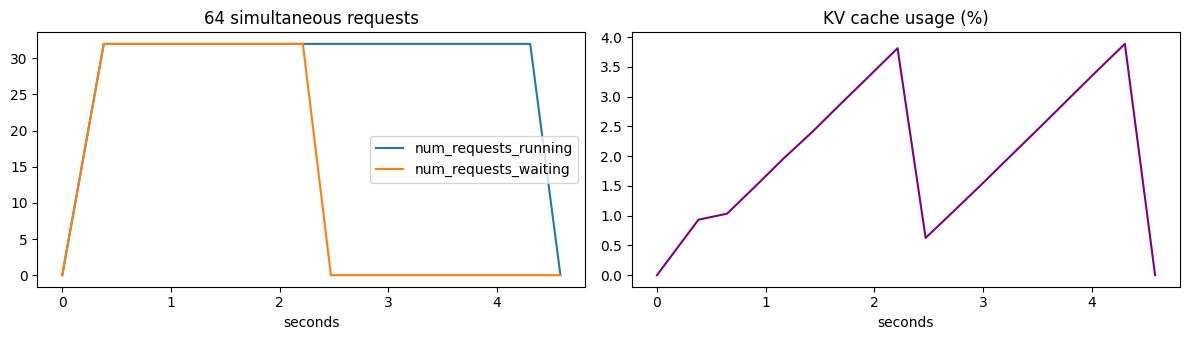

64 requests in 4.6s · 1,787 tokens/s


In [33]:
import pandas as pd, matplotlib.pyplot as plt

# 64 requests at once; the server only decodes 32 together (--max-num-seqs 32), the rest wait in the queue
res, wall, samples = await run_load(64, watch=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.5))
# left: how many requests are in the running batch vs. waiting in the queue, over time
samples.plot(x="t", y=["num_requests_running", "num_requests_waiting"], ax=ax1)
ax1.set_title("64 simultaneous requests"); ax1.set_xlabel("seconds")
# right: fraction of the KV cache pool in use (the metric is called kv_cache_usage_perc or gpu_cache_usage_perc)
kv_col = [c for c in samples.columns if "cache_usage" in c][0]
ax2.plot(samples["t"], samples[kv_col] * 100, color="purple")
ax2.set_title("KV cache usage (%)"); ax2.set_xlabel("seconds")
plt.tight_layout(); plt.show()
# total throughput: all generated tokens over the wall-clock time
print(f"{len(res)} requests in {wall:.1f}s · {res.tokens.sum() / wall:,.0f} tokens/s")

### How to read the plots

**Left: running vs waiting.**
- The server decodes at most 32 requests together (`--max-num-seqs 32`). Of our 64 requests, **32 run** and **32 wait** in the queue.
- At about 2.2 s the first 32 finish. The 32 waiting ones **join the batch** (orange falls to 0, blue stays at 32), and finish at about 4.6 s.
- This is **continuous batching**: a free slot is refilled at the next decoding step, without waiting for the whole batch to end.
  Here it looks like two "waves" only because all requests are identical (same length, 128 tokens), so they finish together.
  With real traffic, slots free up one by one and the queue drains smoothly.

**Right: KV cache usage.**
- Each running request keeps its **keys and values** for every token so far (prompt + generated), and every decoding step adds one token to each of them.
  So usage **rises steadily** while a batch is running.
- When a request finishes, vLLM **frees its blocks**. The first 32 finish together, so usage **drops at once** at about 2.2 s.
- It does not fall to 0: the second batch has just started, and its prompts are already in the cache. Then it grows again, until everything is done (about 4.6 s) and the cache is empty.
- The peak is under 4%: 32 short requests need very little memory. The limit here is `max_num_seqs`, **not** KV cache size.

### Throughput vs latency
🔮 **Predict:** as concurrency grows, what happens to total throughput, and to each user's experience?

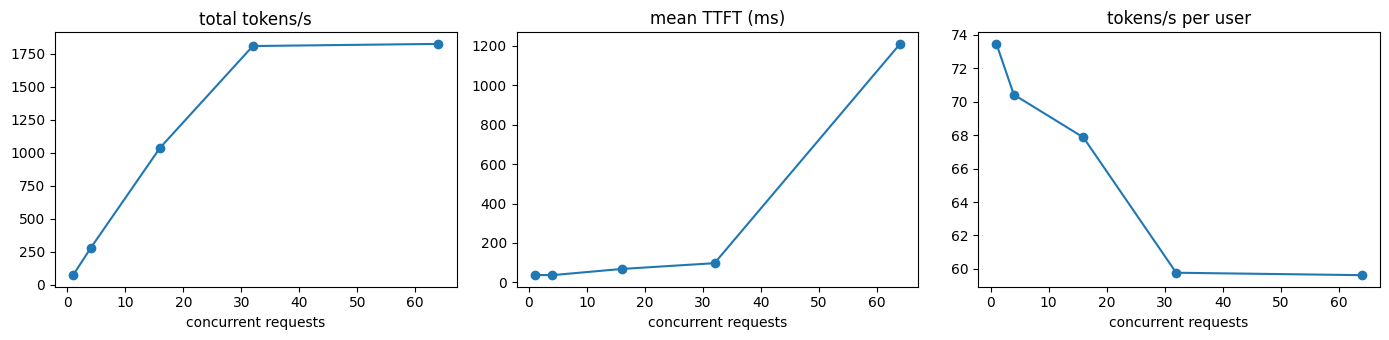

,concurrency,total tokens/s,mean TTFT (ms),tokens/s per user
0,1,71.9,37.8,73.5
1,4,275.3,36.7,70.4
2,16,1036.9,68.1,67.9
3,32,1807.3,97.4,59.8
4,64,1823.5,1209.6,59.6


In [34]:
rows = []
for c in [1, 4, 16, 32, 64]:
    res, wall, _ = await run_load(c)
    rows.append({"concurrency": c,
                 "total tokens/s": res.tokens.sum() / wall,
                 "mean TTFT (ms)": res.ttft.mean() * 1000,
                 "tokens/s per user": (res.tokens / (res.latency - res.ttft)).mean()})
sweep = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes, ["total tokens/s", "mean TTFT (ms)", "tokens/s per user"]):
    ax.plot(sweep.concurrency, sweep[col], marker="o"); ax.set_title(col); ax.set_xlabel("concurrent requests")
plt.tight_layout(); plt.show()
sweep.round(1)

- **Total throughput** rises with concurrency (batching), then flattens.
  - Decoding is **memory-bound**: each step reads all the weights from GPU memory, whether it serves 1 request or 32. More requests share that cost, so tokens/s grows almost linearly (72 → 275 → 1,037 → 1,807 tokens/s for 1, 4, 16, 32 requests).
  - At 32 the batch is full (`--max-num-seqs 32`). Going to 64 adds nothing (1,807 → 1,824 tokens/s): the extra requests only wait in the queue.
- **Per-user speed** drops slowly; **TTFT** jumps once requests start queueing (above 32).
  - Per user, speed stays close to the single-request value (74 → 60 tokens/s at 32): batching is nearly free for each user, because the cost is shared.
  - TTFT (time to first token) is about 40-100 ms while a slot is free. At 64 requests it jumps to about 1.2 s: half of the requests must wait for a running one to finish before their prefill can even start. The user feels this as "the answer takes a second to begin".
- Serving = choosing a point on this **throughput vs latency** trade-off.
  - A higher batch size (`max_num_seqs`) gives more total tokens/s, so a lower cost per token, but each user is a bit slower and the queue is longer when the server is full.
  - A lower one gives a more responsive server but serves fewer users per GPU. The right point depends on the product: an interactive chat wants a low TTFT, an offline batch job wants maximum throughput.

✏️ **Try at home:** restart the container with `--max-num-seqs 128` and re-run the sweep.

---
## Block 6 · ✂️ Prefix caching

Many requests share the same beginning (a long system prompt, a document, few-shot examples).
vLLM keeps the KV blocks of that prefix and **reuses** them, skipping their prefill.

🔮 **Predict:** same long (~6,000-token) system prompt, sent 3 times. Will the requests take the same time?

In [35]:
import uuid

def long_system_prompt():
    nonce = uuid.uuid4().hex                       # makes the prefix new, so it is not cached yet
    rules = " ".join(f"Rule {i}: always be polite, precise and helpful to the customer." for i in range(450))
    return f"[{nonce}] You are a customer-support assistant. {rules}"

def timed_request(system, question):
    t0 = time.perf_counter()
    client.chat.completions.create(model=MODEL, max_tokens=1,       # 1 token: the time is mostly prefill
        messages=[{"role": "system", "content": system}, {"role": "user", "content": question}])
    return (time.perf_counter() - t0) * 1000

system = long_system_prompt()
n_tok = len(requests.post(f"{BASE_URL}/tokenize", headers=HEADERS, json={"model": MODEL, "prompt": system}).json()["tokens"])
print(f"system prompt: {n_tok:,} tokens\n")
for i, q in enumerate(["Where is my order?", "How do I get a refund?", "Can I change my address?"]):
    print(f"request {i + 1} (same prefix) : {timed_request(system, q):6.0f} ms")
print(f"new prefix every time      : {timed_request(long_system_prompt(), 'Where is my order?'):6.0f} ms")

hits = [l for l in requests.get(f"{BASE_URL}/metrics").text.splitlines()
        if "prefix_cache" in l and not l.startswith("#")]
print("\n" + "\n".join(hits))

system prompt: 7,575 tokens

request 1 (same prefix) :    678 ms
request 2 (same prefix) :     42 ms
request 3 (same prefix) :     43 ms
new prefix every time      :    639 ms

vllm:prefix_cache_queries_total{engine="0",model_name="Qwen/Qwen2.5-1.5B-Instruct"} 40236.0
vllm:prefix_cache_queries_created{engine="0",model_name="Qwen/Qwen2.5-1.5B-Instruct"} 1.794237822741309e+09
vllm:prefix_cache_hits_total{engine="0",model_name="Qwen/Qwen2.5-1.5B-Instruct"} 22976.0
vllm:prefix_cache_hits_created{engine="0",model_name="Qwen/Qwen2.5-1.5B-Instruct"} 1.7942378227413192e+09
vllm:external_prefix_cache_queries_total{engine="0",model_name="Qwen/Qwen2.5-1.5B-Instruct"} 0.0
vllm:external_prefix_cache_queries_created{engine="0",model_name="Qwen/Qwen2.5-1.5B-Instruct"} 1.7942378227413282e+09
vllm:external_prefix_cache_hits_total{engine="0",model_name="Qwen/Qwen2.5-1.5B-Instruct"} 0.0
vllm:external_prefix_cache_hits_created{engine="0",model_name="Qwen/Qwen2.5-1.5B-Instruct"} 1.7942378227413373e+09


The first request pays the full prefill; the next ones reuse the cached KV blocks (the PagedAttention blocks from the lecture),
so they only compute the new question. This is why API providers sell **cached input tokens** at a discount.

---
## Block 7 · Benchmarking with `vllm bench serve`

Our load test was a toy. vLLM ships an official benchmark client that reports the metrics from the lecture:

| Metric | Meaning |
|---|---|
| **TTFT** | Time To First Token (queue + prefill) |
| **TPOT** | Time Per Output Token, after the first one (decode speed per user) |
| **ITL** | Inter-Token Latency: time between consecutive tokens |
| **Request / output throughput** | Requests per second / generated tokens per second, for the whole server |

### Run it (terminal), inside the container
```bash
docker exec vllm-lab \
  vllm bench serve \
    --model Qwen/Qwen2.5-1.5B-Instruct \
    --dataset-name random --random-input-len 512 --random-output-len 128 \
    --num-prompts 200 --max-concurrency 16
```
- `--dataset-name random`: synthetic prompts of a fixed length (also: `sharegpt` for real conversations)
- `--max-concurrency`: how many requests in flight at once; `--request-rate` instead sets arrivals per second
- `OPENAI_API_KEY`: the benchmark sends it as the Bearer token

For production-grade load testing see also [GuideLLM](https://github.com/vllm-project/guidellm).

### A sweep from the notebook
Runs the benchmark at several concurrencies and reads the JSON results from the shared `bench/` folder.

In [36]:
BENCH_DIR = "bench"           # host folder mounted at /bench in the container

for c in [1, 8, 32]:
    print(f"running concurrency {c} ...")
    subprocess.run(["docker", "exec", "-e", f"OPENAI_API_KEY={API_KEY}", "vllm-lab",
                    "vllm", "bench", "serve", "--model", MODEL,
                    "--dataset-name", "random", "--random-input-len", "512", "--random-output-len", "128",
                    "--num-prompts", str(max(4 * c, 40)), "--max-concurrency", str(c),
                    "--save-result", "--result-dir", "/bench", "--result-filename", f"c{c}.json"],
                   check=True, capture_output=True)

rows = []
for c in [1, 8, 32]:
    r = json.load(open(f"{BENCH_DIR}/c{c}.json"))
    rows.append({"concurrency": c, "req/s": r["request_throughput"], "output tok/s": r["output_throughput"],
                 "mean TTFT ms": r["mean_ttft_ms"], "p99 TTFT ms": r["p99_ttft_ms"],
                 "mean TPOT ms": r["mean_tpot_ms"], "mean ITL ms": r["mean_itl_ms"]})
pd.DataFrame(rows).round(1)

running concurrency 1 ...
running concurrency 8 ...
running concurrency 32 ...


,concurrency,req/s,output tok/s,mean TTFT ms,p99 TTFT ms,mean TPOT ms,mean ITL ms
0,1,0.6,71.6,46.0,56.3,13.7,13.7
1,8,4.2,534.3,57.5,65.1,14.6,14.6
2,32,10.4,1332.8,441.1,973.3,20.6,20.6


✏️ **Try at home**
- Compare `--random-input-len 2048 --random-output-len 64` (prefill-heavy) with `64 / 1024` (decode-heavy): which metrics change?
- Use `--request-rate 2, 5, 10` instead of `--max-concurrency`: where does TTFT explode?


## Clean up
```bash
docker stop vllm-lab && docker rm vllm-lab
```